Referências: https://www.geeksforgeeks.org/machine-learning/xgboost-parameters/


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

df = pd.read_csv("dataset.csv")

In [18]:
# Cross Validation
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

In [11]:
X = df.iloc[:, 1:17]
y = df.iloc[:, -1]

#sem muitos teste para ajustar o modelo seu primeiro resultado (0.86) já foi melhor que o random forest com ajustes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = XGBClassifier()

scores = cross_val_score(model, X, y, cv=kf, scoring="accuracy")
average = np.mean(scores)

print(f"Score para cada pedaço: {[round(score, 4) for score in scores]}")
print(f"Média de resultado: {average:.2f}")

model.fit(X_train, y_train)
y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Score for each fold: [np.float64(0.8579), np.float64(0.8663)]
Average R² across 2 folds: 0.86
Accuracy: 0.865


In [27]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


modelo_ajustado = XGBClassifier(learning_rate=0.1,
                                n_estimators=300,
                                max_depth=3,
                                subsample=0.8)

scores = cross_val_score(modelo_ajustado, X, y, cv=kf, scoring="accuracy")
average = np.mean(scores)

print(f"Score for each fold: {[round(score, 4) for score in scores]}")
print(f"Average R² across {k} folds: {average:.2f}")

modelo_ajustado.fit(X_treino, y_treino)
y_predc = modelo_ajustado.predict(X_teste)


accuracy = accuracy_score(y_teste, y_predc)
print("Accuracy:", accuracy)

Score for each fold: [np.float64(0.8793), np.float64(0.879), np.float64(0.8727), np.float64(0.8803), np.float64(0.875)]
Average R² across 5 folds: 0.88
Accuracy: 0.882


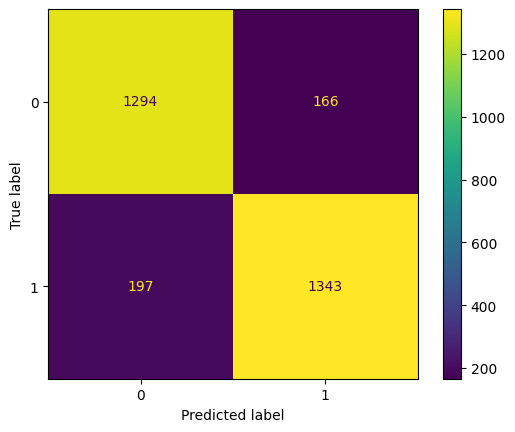

In [6]:
# Cria a matriz de confusão
cm = confusion_matrix(y_teste, y_predc)

ConfusionMatrixDisplay(confusion_matrix=cm).plot();

In [29]:
# Calcula a probabilidade de vitoria
probabilities = modelo_ajustado.predict_proba(X_teste)
indice_vitoria = list(modelo_ajustado.classes_).index(1)

# Extraindo a probabilidade de vitória em porcentagem
chances_vitoria = probabilities[:, indice_vitoria] * 100

# Exibindo os resultados
resultados = pd.DataFrame({
    "Resultado real": y_teste.values,
    "Chance de vitória (%)": chances_vitoria,
    "Previsão do modelo": modelo_ajustado.predict(X_teste)
})

print(resultados)

      Resultado real  Chance de vitória (%)  Previsão do modelo
0                  1              98.052681                   1
1                  0              53.009445                   1
2                  0              13.012118                   0
3                  0              15.473864                   0
4                  0              21.466616                   0
...              ...                    ...                 ...
2995               1              69.811539                   1
2996               1              94.176903                   1
2997               0               0.009496                   0
2998               0               9.191215                   0
2999               0              47.819981                   0

[3000 rows x 3 columns]
